<a href="https://colab.research.google.com/github/fuaadrahman/Exploratory-Data-Analysis-EDA-/blob/main/Mobile_Users_Behavior.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  # MOBILE USERS BEHAVIOR

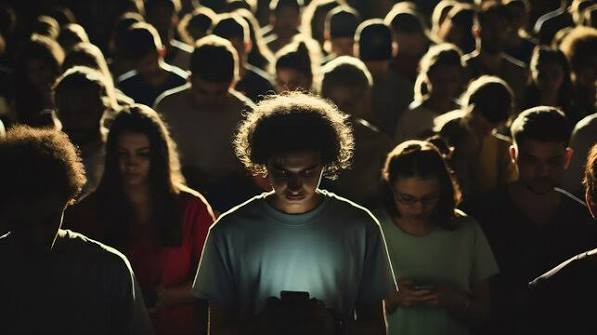

Importing libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as snss

Dataset

In [ ]:
D=pd.read_csv('/content/drive/MyDrive/user_behavior_dataset.csv')
D.head()

,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class
0,1,Google Pixel 5,Android,393,6.4,1872,67,1122,40,Male,4
1,2,OnePlus 9,Android,268,4.7,1331,42,944,47,Female,3
2,3,Xiaomi Mi 11,Android,154,4.0,761,32,322,42,Male,2
3,4,Google Pixel 5,Android,239,4.8,1676,56,871,20,Male,3
4,5,iPhone 12,iOS,187,4.3,1367,58,988,31,Female,3


Last 5 values

In [ ]:
D.tail()

,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class
695,696,iPhone 12,iOS,92,3.9,1082,26,381,22,Male,2
696,697,Xiaomi Mi 11,Android,316,6.8,1965,68,1201,59,Male,4
697,698,Google Pixel 5,Android,99,3.1,942,22,457,50,Female,2
698,699,Samsung Galaxy S21,Android,62,1.7,431,13,224,44,Male,1
699,700,OnePlus 9,Android,212,5.4,1306,49,828,23,Female,3


Shape of dataset

In [ ]:
D.shape

(700, 11)

In [ ]:
D.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   User ID                     700 non-null    int64  
 1   Device Model                700 non-null    object 
 2   Operating System            700 non-null    object 
 3   App Usage Time (min/day)    700 non-null    int64  
 4   Screen On Time (hours/day)  700 non-null    float64
 5   Battery Drain (mAh/day)     700 non-null    int64  
 6   Number of Apps Installed    700 non-null    int64  
 7   Data Usage (MB/day)         700 non-null    int64  
 8   Age                         700 non-null    int64  
 9   Gender                      700 non-null    object 
 10  User Behavior Class         700 non-null    int64  
dtypes: float64(1), int64(7), object(3)
memory usage: 60.3+ KB


Duplicate values

In [ ]:
D.isna().sum()

,0
User ID,0
Device Model,0
Operating System,0
App Usage Time (min/day),0
Screen On Time (hours/day),0
Battery Drain (mAh/day),0
Number of Apps Installed,0
Data Usage (MB/day),0
Age,0
Gender,0


Device which model has the most users

In [ ]:
D["Device Model"].value_counts().head(1)

,count
Device Model,
Xiaomi Mi 11,146


In [ ]:
#Which operating system has more users?
D["Operating System"].value_counts().head(1)

,count
Operating System,
Android,554


Average daily app usage for each device model

In [ ]:
D.groupby("Device Model")["App Usage Time (min/day)"].mean()

,App Usage Time (min/day)
Device Model,
Google Pixel 5,267.788732
OnePlus 9,270.383459
Samsung Galaxy S21,266.421053
Xiaomi Mi 11,268.452055
iPhone 12,282.020548


Total data usage for each operating system

In [ ]:
D.groupby("Operating System")["Data Usage (MB/day)"].sum()

,Data Usage (MB/day)
Operating System,
Android,509856
iOS,140964


Number of users in each behavior class

In [ ]:
D["User Behavior Class"].value_counts().sort_index()

,count
User Behavior Class,
1,136
2,146
3,143
4,139
5,136


gender Which has the higher average screen-on time

In [ ]:
D.groupby("Gender")["Screen On Time (hours/day)"].mean()

,Screen On Time (hours/day)
Gender,
Female,5.261310
Male,5.283242


Average screen-on time by age

In [ ]:
D.groupby("Age")["Screen On Time (hours/day)"].mean().head()

,Screen On Time (hours/day)
Age,
18,5.490909
19,4.750000
20,5.547059
21,6.376471
22,6.304167


 Maximum Age and First Five Values in Each Column

In [ ]:
print("Maximum Age:", D["Age"].max())

for col in D.columns:
    print("\nColumn:", col)
    print(D[col].head())
    print("-" * 40)

Maximum Age: 59

Column: User ID
0    1
1    2
2    3
3    4
4    5
Name: User ID, dtype: int64
----------------------------------------

Column: Device Model
0    Google Pixel 5
1         OnePlus 9
2      Xiaomi Mi 11
3    Google Pixel 5
4         iPhone 12
Name: Device Model, dtype: object
----------------------------------------

Column: Operating System
0    Android
1    Android
2    Android
3    Android
4        iOS
Name: Operating System, dtype: object
----------------------------------------

Column: App Usage Time (min/day)
0    393
1    268
2    154
3    239
4    187
Name: App Usage Time (min/day), dtype: int64
----------------------------------------

Column: Screen On Time (hours/day)
0    6.4
1    4.7
2    4.0
3    4.8
4    4.3
Name: Screen On Time (hours/day), dtype: float64
----------------------------------------

Column: Battery Drain (mAh/day)
0    1872
1    1331
2     761
3    1676
4    1367
Name: Battery Drain (mAh/day), dtype: int64
---------------------------------

Most-Used Device Models

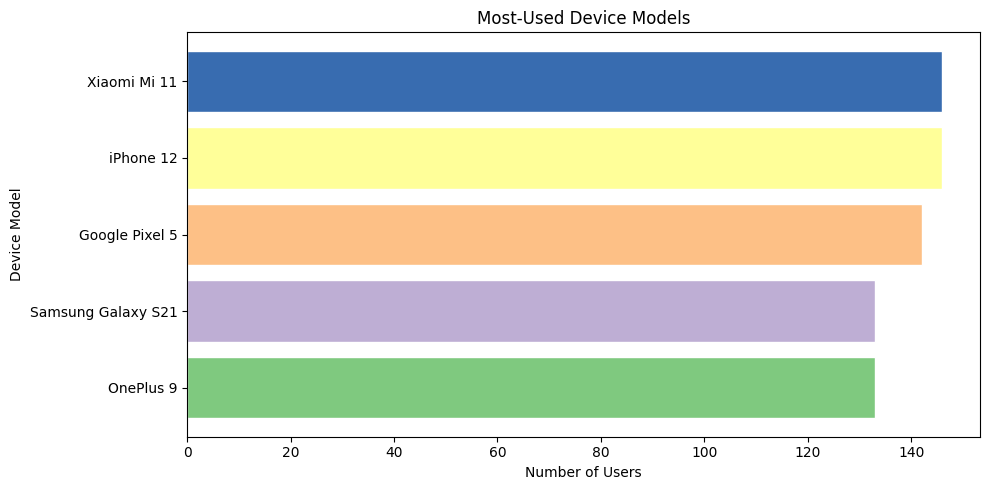

In [ ]:
A=D["Device Model"].value_counts().head(10).sort_values()

colors = plt.cm.Accent(range(len(A)))
plt.figure(figsize=(10,5))

plt.barh(
    A.index,
    A.values,
    color=colors,
    edgecolor="white"
)

plt.title("Most-Used Device Models")
plt.xlabel("Number of Users")
plt.ylabel("Device Model")
plt.tight_layout()
plt.show()

Key Insight:
- Xiaomi Mi 11 and iPhone 12 are the most common device models, with 146 users each.
- Google Pixel 5 follows with 142 users.
- OnePlus 9 and Samsung Galaxy S21 have the lowest counts, with 133 users each.
- The device counts are fairly close across all five models.

Top Behavior Classes by Users

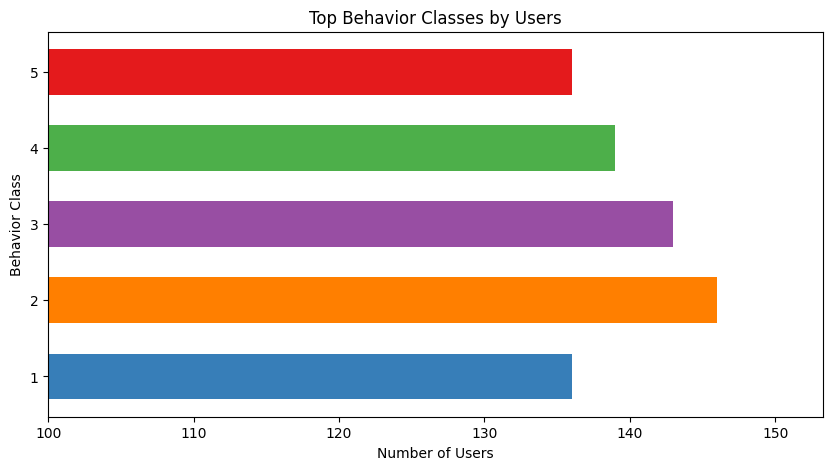

In [ ]:
B = D["User Behavior Class"].value_counts().head(5).sort_values()

colors = plt.cm.Set1(range(len(B)))

plt.figure(figsize=(10, 5))

plt.barh(B.index, B.values, color=colors, height=0.6)

plt.xlim(left=100)
plt.xlabel("Number of Users")
plt.ylabel("Behavior Class")
plt.title("Top Behavior Classes by Users")
plt.show()

Key Insight:
- Behavior Class 2 has the most users, with 146.
- Classes 1 and 5 have the fewest users, with 136 each.
- The class counts are close, ranging from 136 to 146 users.

Users and App Usage

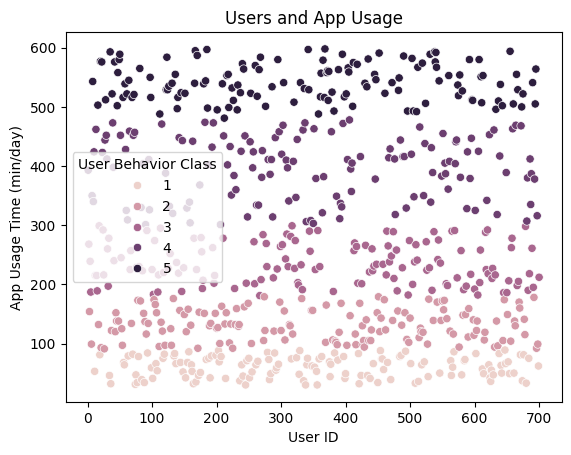

In [ ]:
sns.scatterplot(
    data=D,
    x="User ID",
    y="App Usage Time (min/day)",
    hue="User Behavior Class"
)
plt.title("Users and App Usage")
plt.show()

Key Insight:
- App usage ranges from 30 minutes per day to 598 minutes per day.
- User 368 has the highest app usage: 598 minutes per day and belongs to Behavior Class 5.
- The lowest usage is 30 minutes per day, recorded for Users 245, 338, and 356, all in Behavior Class 1.
- Class 1 users range from 30–89 minutes of app use, while Class 5 users range from 481–598 minutes.
- User ID is just an identifier, and the points show no meaningful trend across IDs.

Users by Behavior Class

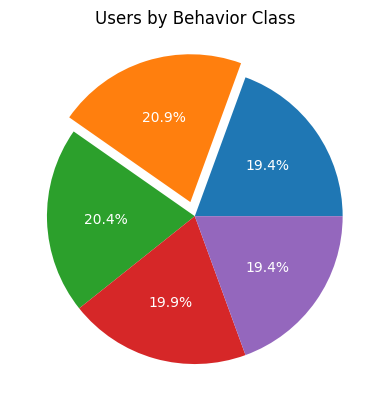

In [ ]:
P= D["User Behavior Class"].value_counts().sort_index()

plt.pie(
    P.values,
    autopct="%1.1f%%",
    explode=[0, 0.1, 0, 0, 0],
    textprops={"color": "white"}
)

plt.title("Users by Behavior Class")
plt.ylabel("")
plt.show()

Key Insight:
- Behavior Class 2 represents the largest share of users, at 20.9%.
- Classes 1 and 5 each represent the smallest share, at 19.4%.
- The pie chart shows that users are distributed fairly evenly across the five behavior classes.


-----------------------------------------------------------------------------


-----------------------------------------------------------------------------

Recommendations
1. Help users manage long screen time. Class 5 users spend about 9 hours a day using apps on average. Screen-time reminders and break alerts may help them keep track of their usage.
2. Give users tips that match their habits. App use differs across behavior classes, so the same advice may not be useful for everyone.
3. Look more closely at battery drain. The dataset includes battery and app-use information. Comparing these could help show whether people who use apps more also drain their battery faster.
4. Don’t focus on one phone model yet. The number of users is similar across the five models. More analysis is needed to see whether usage differs by model.
5. Study the data further. Comparing usage by age and gender, and looking at data usage, could reveal other useful patterns.